# Problem Set 1
### Cheaper food, better nutrition? Evaluating a staple-food subsidy
#### Group: Jose Eduardo Campos Hernandez, Drishti Khemlani, Madeleine Roberts

##### Data import and cleaning

In [ ]:
# Import packages
library(tidyverse)
library(gt)
library(fixest)

# Import data
staple_households <- read_csv("staple_households.csv", show_col_types = FALSE)
food_energy <- read_csv("food_energy.csv", show_col_types = FALSE)

# cleaning with regex
raw_data <- staple_households |>
  pivot_longer(
    cols          = matches("_(g|price_kg)$"),
    names_to      = c("food", ".value"),
    names_pattern = "(.*)_(g|price_kg)$"
  ) |>
  left_join(food_energy, by = "food") |>
  transmute(
    household_id, region, treated, wave,
    baseline_resources, cash_resources,
    food_spending, other_spending, subsidy_cost,
    food,
    price_g             = price_kg / 1000,
    kcal_per_g,
    grams_consumed      = g,
    food_caloric_intake = grams_consumed * kcal_per_g,
    food_share_spending = grams_consumed * price_g / food_spending * 100
  )

raw_data[sample(nrow(raw_data), 5), ]

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


household_id,region,treated,wave,baseline_resources,cash_resources,food_spending,other_spending,subsidy_cost,food,price_g,kcal_per_g,grams_consumed,food_caloric_intake,food_share_spending
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
H024,A,1,After,7.64,7.64,2.8008,4.8392,0,vegetables,0.0020,0.3,292.0,87.60,20.851185
H083,A,0,After,9.43,9.43,2.7677,6.6623,0,rice,0.0024,3.6,511.3,1840.68,44.337175
H167,A,0,After,12.32,12.32,2.4913,9.8287,0,oil,0.0100,9.0,25.5,229.50,10.235620
H413,B,1,Before,7.59,7.59,2.5413,5.0487,0,oil,0.0100,9.0,16.4,147.60,6.453390
H475,B,0,During,10.70,10.80,2.9399,7.8601,0,oil,0.0100,9.0,24.9,224.10,8.469676


##### **Question 1: Understand the data and make a prediction**
*Before calculating policy effects, record your prediction about how households will respond to cheaper rice and whether calorie intake will increase. State the reasoning and assumptions behind your prediction.*

[MR comment]: we could start with a basic prediction like this one

We predict that households will respond to cheaper rice by consuming more rice, therefore for their calorie intake to increase. We assume a downward-sloping demand curve where the Q demanded of rice increases as price of rice decreases. More rice consumed will result in more calorie intake.

[MR comment]: or add a few caveats
1. Substitution effect: rice is now relatively cheaper, which pushes rice consumption up.
2. Income effect: rice takes a large share of the budget, so a 25% cut frees up real money. Whether that money pushes rice up or down depends on whether rice is a normal or inferior good for these households.
Calories ≠ rice: even if rice rises, the freed money can move into fish or oil (oil is very calorie-dense at 9 kcal/g), vegetables, or non-food spending.

[JE] Rice is the staple food in this sample: it provides the cheapest source of calories and forms the base of household diets, much as potatoes or maize tortillas do in other contexts. More expensive foods, such as fish, add taste and variety. This structure shapes our prediction. If households already cover a basic calorie need with rice and value variety, a lower rice price frees resources that they may spend on preferred foods rather than on additional rice. Whether rice consumption responds to income is an empirical question that the baseline data allow us to examine.

 *Explore and audit the dataset. What do you need to check before trusting an analysis of this pilot? Give a concise account of the sample, the policy as implemented and any data issues. Construct a measure of the policy’s stated outcome, explaining its units and any transformations you make.*

The sample follows 480 households in two regions: 240 for both A and B regions, with 50% as control group and 50% as treatment group in both. The data is captured in three different waves in time (before, during and after treatment). Our checks show that there is no survey attrition, no missing values and exactly one row per household per wave. Treatment and region stay the same for each household across waves. Unit of observation: household × wave, N = 1,440 (480 households × 3 waves). Randomisation is at household level within region.

Before trusting an analysis of this pilot we need to validate the randomisation by testing, in the before wave, whether households who received the subsidy and households who didn't receive the subsidy are balanced across baseline characteristics relevant to our outcome (calorie intake).

Table 1 provides means for treatment and control groups for key variables in the baseline survey and the differences of means. Overall, none of the differences is statistically significant. Splitting the sample by region confirms this result.

In [ ]:
labels <- c(baseline_resources   = "Baseline resources (per person/day)",
            food_spending        = "Food spending (per person/day)",
            other_spending       = "Other spending (per person/day)",
            rice_share           = "Share of food spending on rice (%)",
            total_caloric_intake = "Calorie intake (kcal/person/day)",
            kcal_rice            = "  Rice (kcal)",
            kcal_fish            = "  Fish (kcal)",
            kcal_vegetables      = "  Vegetables (kcal)",
            kcal_oil             = "  Oil (kcal)")

# One row per household in the Before wave
food_kcal <- raw_data |>
  filter(wave == "Before") |>
  select(household_id, food, food_caloric_intake) |>
  pivot_wider(names_from = food, values_from = food_caloric_intake, names_prefix = "kcal_")

check_data <- raw_data |>
  filter(wave == "Before", food == "rice") |>
  select(household_id, region, treated, baseline_resources, food_spending, other_spending,
         rice_share = food_share_spending) |>
  left_join(food_kcal, by = "household_id") |>
  mutate(total_caloric_intake = kcal_rice + kcal_fish + kcal_vegetables + kcal_oil)

# Stack the full sample and each region, then test every variable in one pass
balance <- bind_rows(check_data |> mutate(sample = "Total"),
                     check_data |> mutate(sample = paste("Region", region))) |>
  select(sample, treated, all_of(names(labels))) |>
  pivot_longer(-c(sample, treated)) |>
  group_by(sample, name) |>
  summarise(Treatment  = mean(value[treated == 1]),
            Comparison = mean(value[treated == 0]),
            p_value    = t.test(value[treated == 1], value[treated == 0])$p.value,
            .groups = "drop") |>
  mutate(stars      = case_when(p_value < 0.01 ~ "***",
                                p_value < 0.05 ~ "**",
                                p_value < 0.10 ~ "*",
                                TRUE           ~ ""),
         Difference = paste0(sprintf("%.2f", Treatment - Comparison), stars),
         Variable   = factor(labels[name], levels = labels))

balance_wide <- balance |>
  select(sample, Variable, Treatment, Comparison, Difference) |>
  pivot_wider(names_from  = sample,
              values_from = c(Treatment, Comparison, Difference),
              names_glue  = "{sample}|{.value}") |>
  arrange(Variable) |>
  select(Variable, starts_with("Total"), starts_with("Region A"), starts_with("Region B"))

tbl1 <- balance_wide |>
  gt(rowname_col = "Variable") |>
  tab_header(title = "Table 1: Covariate balance in the Before wave") |>
  tab_spanner_delim(delim = "|") |>
  fmt_number(columns = matches("Treatment|Comparison"), decimals = 2) |>
  cols_align(align = "center") |>
  tab_style(style = list(cell_fill(color = "grey85"), cell_text(weight = "bold")),
            locations = cells_column_spanners()) |>
  opt_row_striping() |>
  tab_source_note("Means in the Before wave. Difference = Treatment − Comparison; stars from Welch two-sample t-tests: * p < 0.10, ** p < 0.05, *** p < 0.01. N = 240 households per group in Total; 120 per group in each region.")

IRdisplay::display_html(as_raw_html(tbl1))

"Means in the Before wave. Difference = Treatment − Comparison; stars from Welch two-sample t-tests: * p < 0.10, ** p < 0.05, *** p < 0.01. N = 240 households per group in Total; 120 per group in each region."


The outcome is household calorie intake as measured by kcal per person per day, calculated as 3.6·rice_g + 1.2·fish_g + 0.3·veg_g + 9·oil_g

## Question 2: Explore the data
*Before evaluating the policy, explore the main features of the data. Choose a small set of descriptive tables and figures that help you understand households’ consumption, resources and spending, and how these vary across the sample and over time. Describe the patterns you find most informative or surprising. What questions do they raise? How should these patterns inform your subsequent policy evaluation? Explain why you selected each table or figure.*

Cash resources could confound the effect we want to estimate only if they changed differently for treated and control households. Figure 1 shows mean cash resources, without the subsidy, by group, wave and region. Two patterns stand out. First, cash resources rise in the During wave and return to their initial level in the After wave, but this movement is common to treated and control households in both regions. Second, in region B treated households hold slightly more cash than control households in every wave; this gap is constant over time and is not statistically significant at baseline (Table 1). Neither pattern threatens the evaluation: the comparison with control households absorbs changes common to both groups, and household fixed effects absorb constant differences between them.

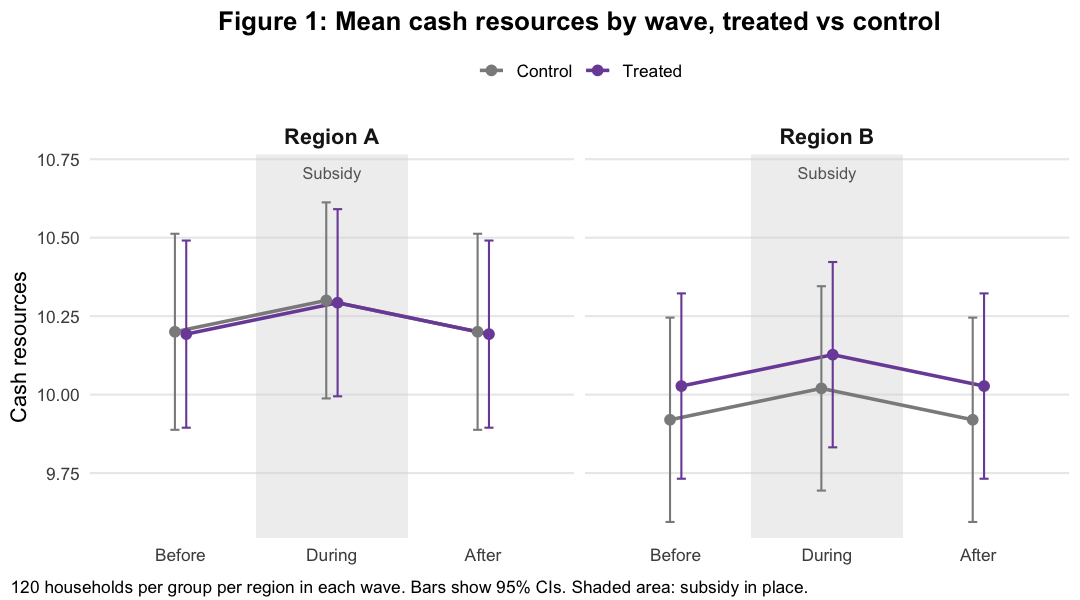

In [ ]:
# Plot settings: spacing between groups and figure size
dodge <- position_dodge(0.15)
options(repr.plot.width = 9, repr.plot.height = 5)

# Data: one row per household-wave, then mean and SE of cash resources
# by region, wave and group. "Region A"/"Region B" labels are created here.
raw_data |>
  filter(food == "rice") |>
  mutate(wave  = factor(wave, levels = c("Before", "During", "After")),
         group = if_else(treated == 1, "Treated", "Control"),
         region = paste("Region", region)) |>
  group_by(region, wave, group) |>
  summarise(mean = mean(cash_resources),
            se = sd(cash_resources) / sqrt(n()),
            .groups = "drop") |>

  # Axes: wave on x, mean on y, one line per group
  ggplot(aes(wave, mean, colour = group, group = group)) +

  # Shaded area and label for the During wave (subsidy in place)
  annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf,
           ymax = Inf, fill = "grey85", alpha = 0.4) +
  annotate("text", x = 2, y = Inf, label = "Subsidy",
           vjust = 2, colour = "grey40", size = 3.5) +

  # Means with 95% confidence intervals
  geom_line(position = dodge, linewidth = 1) +
  geom_point(position = dodge, size = 2.5) +
  geom_errorbar(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se),
                width = 0.12, position = dodge) +

  # One panel per region; panel titles come from the region column
  facet_wrap(~ region) +

  # Scales: discrete x axis and group colours
  scale_x_discrete() +
  # expand = option to define extra space
  # expansion(mult = ...) indicates the space is measured as proportion of the range of the data. # nolint: line_length_linter.
  # mult comes from 'multiplicative'
  # Proportion of extra space below and above: c(0.05, 0.15)
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15))) +
  scale_colour_manual(values = c(Control = "grey55", Treated = "#7b4fa6")) +

  # Titles and notes
  labs(title = "Figure 1: Mean cash resources by wave, treated vs control",
       x = NULL, y = "Cash resources", colour = NULL,
       caption = "120 households per group per region in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +

  # Visual style: legend on top, light grid, bold panel and plot titles, caption on the left
  theme_minimal(base_size = 13) +
  theme(legend.position = "top",
        panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        strip.text = element_text(face = "bold", size = 13),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0, vjust = -1),
        plot.caption.position = "plot")

For each group, the share of calorie intake by food is the same (Figure 2). Rice represents the major source with 84% of the total, followed by oil with 9%. Fish and vegetables represents each only 4%. 

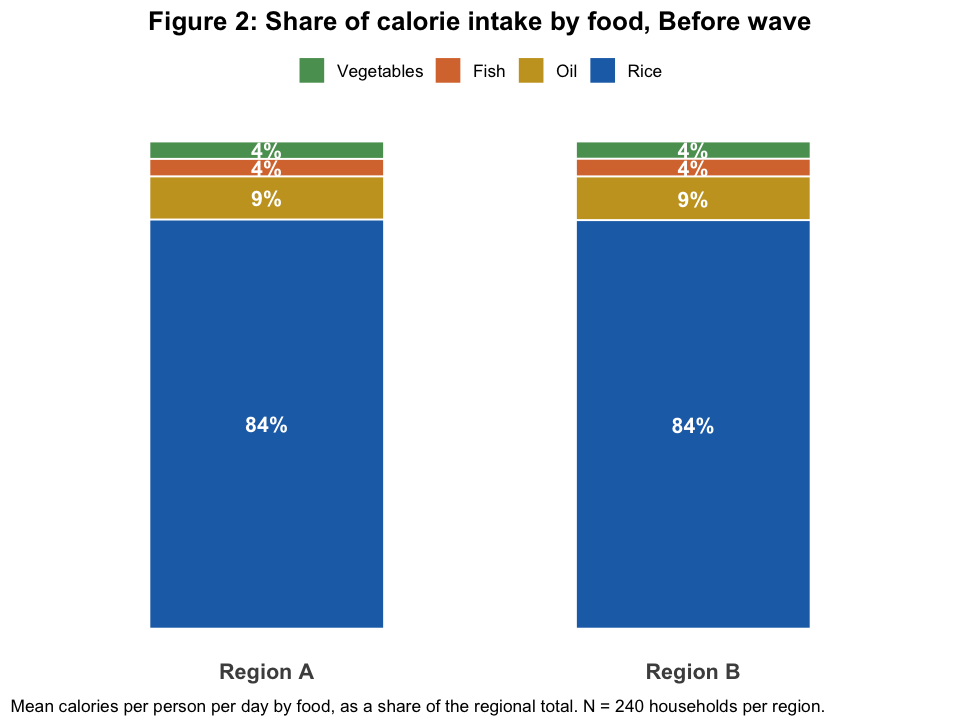

In [20]:
options(repr.plot.width = 8, repr.plot.height = 6)

raw_data |>
  filter(wave == "Before") |>
  group_by(region, food) |>
  summarise(kcal = mean(food_caloric_intake), .groups = "drop") |>
  group_by(region) |>
  mutate(share = kcal / sum(kcal),
         region = paste("Region", region)) |>
  ungroup() |>
  mutate(food = fct_reorder(str_to_title(food), share)) |>
  ggplot(aes(region, share, fill = food)) +
  geom_col(width = 0.55, colour = "white", linewidth = 0.5) +
  geom_text(aes(label = if_else(share >= 0.03, scales::percent(share, accuracy = 1), "")),
            position = position_stack(vjust = 0.5),
            colour = "white", fontface = "bold", size = 4.5) +
  scale_fill_manual(values = c(Rice       = "#1f6fb4",
                               Oil        = "#c9a227",
                               Fish       = "#d9773b",
                               Vegetables = "#5a9e5f")) +
  labs(title = "Figure 2: Share of calorie intake by food, Before wave",
       x = NULL, y = NULL, fill = NULL,
       caption = "Mean calories per person per day by food, as a share of the regional total. N = 240 households per region.") +
  theme_minimal(base_size = 13) +
  theme(legend.position = "top",
        panel.grid = element_blank(),
        axis.text.y = element_blank(),
        axis.text.x = element_text(size = 13, face = "bold"),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0, vjust = -0.8))

Rice is by far the cheapest source of calories: one currency unit buys 1,500 kcal of rice, compared with 150 kcal of vegetables and only 100 kcal of fish, the most expensive source (Table 2). One unit spent on rice therefore provides 15 times as many calories as one unit spent on fish. As a result, a household that shifts spending from rice to fish lowers the calories it obtains per unit spent, and its total calorie intake can fall even when its food spending stays constant or rises. This raises a key question for the evaluation: if the subsidy frees resources, do households spend them on more rice or on more expensive foods such as fish?

In [5]:
cost <- raw_data |>
  filter(wave == "Before") |>
  group_by(food) |>
  summarise(price_kg = mean(price_g) * 1000,
            kcal_g   = mean(kcal_per_g),
            .groups = "drop") |>
  mutate(kcal_per_unit = kcal_g * 1000 / price_kg) |>
  arrange(desc(kcal_per_unit))

tbl3 <- cost |>
  gt(rowname_col = "food") |>
  tab_header(title = "Table 2: Cost of calories by food, Before wave") |>
  cols_label(price_kg = "Price per kg", kcal_g = "kcal per gram", kcal_per_unit = "kcal per currency unit") |>
  fmt_number(columns = c(price_kg, kcal_g), decimals = 2) |>
  fmt_number(columns = kcal_per_unit, decimals = 0) |>
  cols_align(align = "center") |>
  tab_source_note("kcal per currency unit = kcal per gram × 1,000 / price per kg. Under the subsidy, rice costs 2.4 × 0.75 = 1.8 per kg for treated households.")

IRdisplay::display_html(as_raw_html(tbl3))

"kcal per currency unit = kcal per gram × 1,000 / price per kg. Under the subsidy, rice costs 2.4 × 0.75 = 1.8 per kg for treated households."


Figures 3a and 3b relate baseline resources to rice and fish consumption in the Before wave, to check whether richer households eat less rice and more fish. The data show no such pattern: none of the slopes is statistically significant, in the full sample or within either region. In the full sample, one additional currency unit of resources is associated with 0.61 g less rice and 0.2 g more fish per person per day. The regions differ in sign: in region A, rice and fish consumption fall slightly with resources (−1.27 g and −0.08 g), while in region B both rise slightly (0.06 g and 0.51 g). These magnitudes are also small in practical terms: across the full range of resources, about 6 units, the largest slope implies a change of 6 × 1.27 ≈ 8 g of rice, less than 2% of average consumption. The cross-section therefore offers no evidence that rice behaves as an inferior good, and any explanation of the subsidy's effect needs to rest on the experimental comparison rather than on differences between households.

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


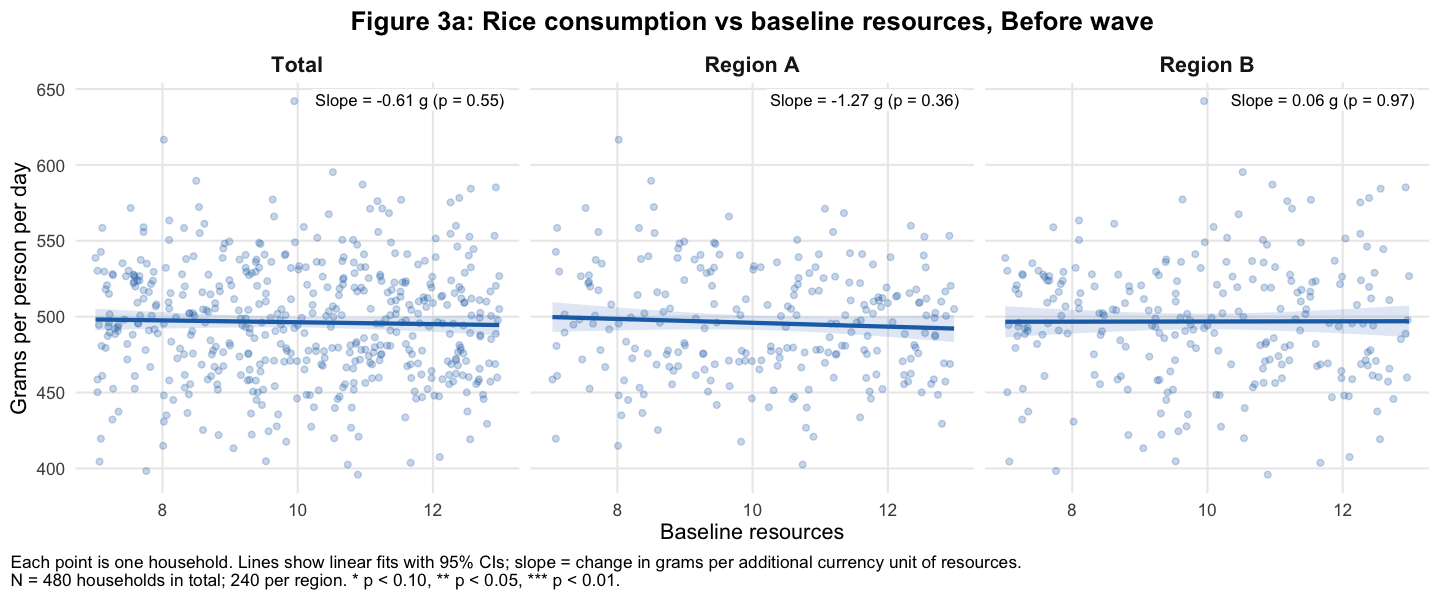

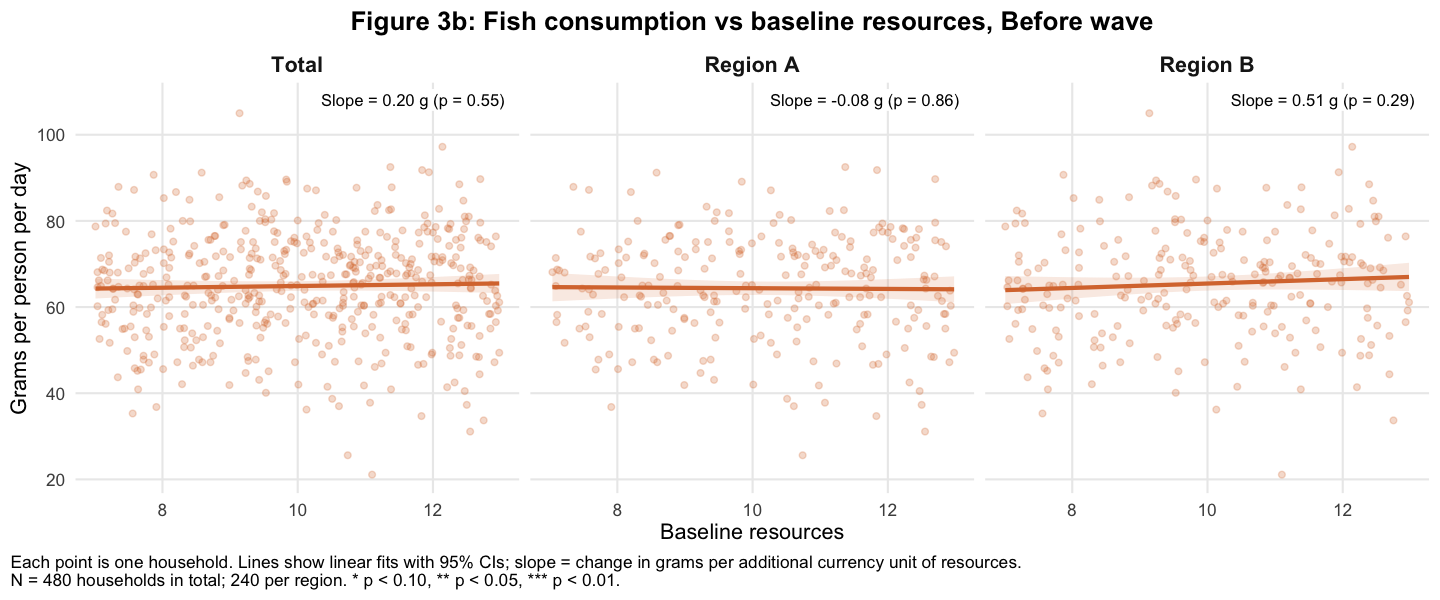

In [22]:
options(repr.plot.width = 12, repr.plot.height = 5)

engel_data <- raw_data |>
  filter(wave == "Before", food %in% c("rice", "fish")) |>
  mutate(region = paste("Region", region))

engel_data <- bind_rows(engel_data,
                        mutate(engel_data, region = "Total")) |>
  mutate(region = factor(region, levels = c("Total", "Region A", "Region B")))

slopes <- engel_data |>
  group_by(region, food) |>
  summarise(slope = coef(lm(grams_consumed ~ baseline_resources))[2],
            p     = summary(lm(grams_consumed ~ baseline_resources))$coefficients[2, 4],
            .groups = "drop") |>
  mutate(stars = case_when(p < 0.01 ~ "***",
                           p < 0.05 ~ "**",
                           p < 0.10 ~ "*",
                           TRUE     ~ ""),
         label = paste0("Slope = ", sprintf("%.2f", slope), " g", stars, " (p = ", sprintf("%.2f", p), ")"))

engel_theme <- theme_minimal(base_size = 13) +
  theme(panel.grid.minor = element_blank(),
        strip.text = element_text(face = "bold", size = 13),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

engel_caption <- "Each point is one household. Lines show linear fits with 95% CIs; slope = change in grams per additional currency unit of resources.\nN = 480 households in total; 240 per region. * p < 0.10, ** p < 0.05, *** p < 0.01."

# Rice
ggplot(filter(engel_data, food == "rice"), aes(baseline_resources, grams_consumed)) +
  geom_point(alpha = 0.25, colour = "#1f6fb4", size = 1.5) +
  geom_smooth(method = "lm", colour = "#1f6fb4", fill = "#1f6fb4", alpha = 0.15, linewidth = 1.2) +
  geom_label(data = filter(slopes, food == "rice"),
             aes(x = Inf, y = Inf, label = label),
             hjust = 1.05, vjust = 1.3, size = 3.5, fill = "white", label.size = 0) +
  facet_wrap(~ region) +
  labs(title = "Figure 3a: Rice consumption vs baseline resources, Before wave",
       x = "Baseline resources",
       y = "Grams per person per day",
       caption = engel_caption) +
  engel_theme

# Fish
ggplot(filter(engel_data, food == "fish"), aes(baseline_resources, grams_consumed)) +
  geom_point(alpha = 0.25, colour = "#d9773b", size = 1.5) +
  geom_smooth(method = "lm", colour = "#d9773b", fill = "#d9773b", alpha = 0.15, linewidth = 1.2) +
  geom_label(data = filter(slopes, food == "fish"),
             aes(x = Inf, y = Inf, label = label),
             hjust = 1.05, vjust = 1.3, size = 3.5, fill = "white", label.size = 0) +
  facet_wrap(~ region) +
  labs(title = "Figure 3b: Fish consumption vs baseline resources, Before wave",
       x = "Baseline resources",
       y = "Grams per person per day",
       caption = engel_caption) +
  engel_theme

## Question 3: Design a credible evaluation
*What comparison would allow you to assess whether the subsidy achieved its objective? Describe the outcome you will evaluate, the counterfactual you need and how the available data can help you approximate it. Explain why your comparison is informative about the policy rather than simply about differences between households or changes over time. State the assumptions your interpretation requires. Choose the tables or plots that would make your evaluation convincing to someone who has not seen the data.*

[MR comment]: I suggest we do a DiD (difference-in-differences) as our empirical strategy to compare changes in caloric intakes for treatment and control groups during and after. DiDs are good because the method exploits some naturally occurring events that change the treatment status of some units over time.

Necessary ingredients:
• Need an event that affects only a sub-population
• Observe the outcome of interest before and after the treatment
• Observe the outcome of interest for both treated and untreated groups

[MR comment]: I had a bit of help from old uni notes + LLM to put the equation together - the only part I'm not confident about is the choice of fixed effects to be region x time

[JE comment]: yes, it is correct since the randomization was made inside each region. So, by definition, it is not the same in A and B.

$$Y_{it} = \alpha_i + \lambda_{r(i)t} + \beta_D\,(T_i \times \text{During}_t) + \beta_A\,(T_i \times \text{After}_t) + \varepsilon_{it}$$

where:

- $Y_{it}$ is the **total** calorie intake of household $i$ in wave $t$, in kcal per person per day, summed over rice, fish, vegetables and oil.
- $\alpha_i$ is a household fixed effect, which absorbs every household characteristic that does not change across waves.
- $\lambda_{r(i)t}$ is a region $\times$ wave fixed effect, which absorbs shocks common to all households in a region in a given wave. Randomisation was done within region, so this matches the design.
- $T_i = 1$ if household $i$ was randomly assigned to the subsidy, and $0$ otherwise.
- $\text{During}_t$ and $\text{After}_t$ are wave indicators. The Before wave is the omitted reference.
- Standard errors are clustered by household, because each household is observed three times.

Including region and time period fixed effects allow our comparison to be informative about the policy because we are controlling for differences between households and changes over time.


DiD ssumptions required:
Unobservables that affect the outcome do not vary differently in time between treated and control units. Without the treatment, the outcome of the treated control units would have changed by the same amount. The potential outcome (y0) or (y1) of the treated and control units change by the same amount between periods 0 and 1 = the Parallel Trends Assumption (PTA).

The PTA translates to:

• Unobservables that affect the outcome in average do not vary differently in
time between treated and control units

• Without the treatment, the average outcome of the treated and control units
would have changed by the same amount

Parallel trends holds by design in expectation, because randomisation makes the two groups the same in every way apart from the subsidy. Table 1 is our evidence.

## Question 4: Assess the evidence
*Carry out your evaluation and report the direction and size of the estimated policy effect. How strong is the evidence for your conclusion? Address uncertainty in a way you can explain, taking account of how the observations were collected.*

*Decide whether a single overall result adequately describes the pilot. Investigate any differences in responses that you think matter for the policy decision, and justify your choices. Revisit your initial prediction: what did you learn, and what remains unresolved?*

Using consumption surveys gathered before, during, and after the subsidy was introduced, we find no evidence that the subsidy improved calorie intake for the pooled sample and infact might harm it --> we find decreased calorie intake, statistically significant treatment effect during. Considering the regions separately, we find that households in Region A especially reduce their intake of calories in response to the price subsidy. Effect goes away after subsidy ends.

In [56]:
regression_data <- regression_data |>
  mutate(region_b = as.integer(region == "B"))

did_a <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
                 household_id + wave,
               data = filter(regression_data, region == "A"), cluster = ~household_id)

did_b <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
                 household_id + wave,
               data = filter(regression_data, region == "B"), cluster = ~household_id)

did_diff <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after +
                    treated:wave_during:region_b + treated:wave_after:region_b |
                    household_id + region^wave,
                  data = regression_data, cluster = ~household_id)

tbl5 <- modelsummary(list("Pooled" = did, "Region A" = did_a, "Region B" = did_b, "Difference" = did_diff),
                     coef_map = c("treated:wave_during"          = "Treated × During",
                                  "treated:wave_after"           = "Treated × After",
                                  "treated:wave_during:region_b" = "Treated × During × Region B",
                                  "treated:wave_after:region_b"  = "Treated × After × Region B"), # nolint
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs", "r.squared"),
                     output  = "gt") |>
  tab_header(title = "Table 3: Effect of the rice subsidy on calorie intake, by region") |>
  tab_source_note("Dependent variable: calorie intake in kcal per person per day. Household fixed effects; wave fixed effects in the regional models and region × wave fixed effects in the pooled and difference models. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl5))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: calorie intake in kcal per person per day. Household fixed effects; wave fixed effects in the regional models and region × wave fixed effects in the pooled and difference models. Standard errors clustered by household in parentheses.


In [57]:
food_data <- raw_data |>
  mutate(wave_during = as.integer(wave == "During"),
         wave_after  = as.integer(wave == "After"))

regression_per_food <- function(f, r) {
  feols(grams_consumed ~ treated:wave_during + treated:wave_after | household_id + wave,
        data = filter(food_data, food == f, region == r), cluster = ~household_id)
}

tbl6 <- modelsummary(list("Rice, Region A" = regression_per_food("rice", "A"),
                          "Rice, Region B" = regression_per_food("rice", "B"),
                          "Fish, Region A" = regression_per_food("fish", "A"),
                          "Fish, Region B" = regression_per_food("fish", "B")),
                     coef_map = c("treated:wave_during" = "Treated × During",
                                  "treated:wave_after"  = "Treated × After"),
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs", "r.squared"),
                     output  = "gt") |>
  tab_header(title = "Table 4: Effect of the rice subsidy on rice and fish consumption, by region") |>
  tab_source_note("Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl6))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.


In [58]:
tbl7 <- modelsummary(list("Vegetables, Region A" = regression_per_food("vegetables", "A"),
                          "Vegetables, Region B" = regression_per_food("vegetables", "B"),
                          "Oil, Region A" = regression_per_food("oil", "A"),
                          "Oil, Region B" = regression_per_food("oil", "B")),
                     coef_map = c("treated:wave_during" = "Treated × During",
                                  "treated:wave_after"  = "Treated × After"),
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs", "r.squared"),
                     output  = "gt") |>
  tab_header(title = "Table 5: Effect of the rice subsidy on vegetables and oil consumption, by region") |>
  tab_source_note("Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl7))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.


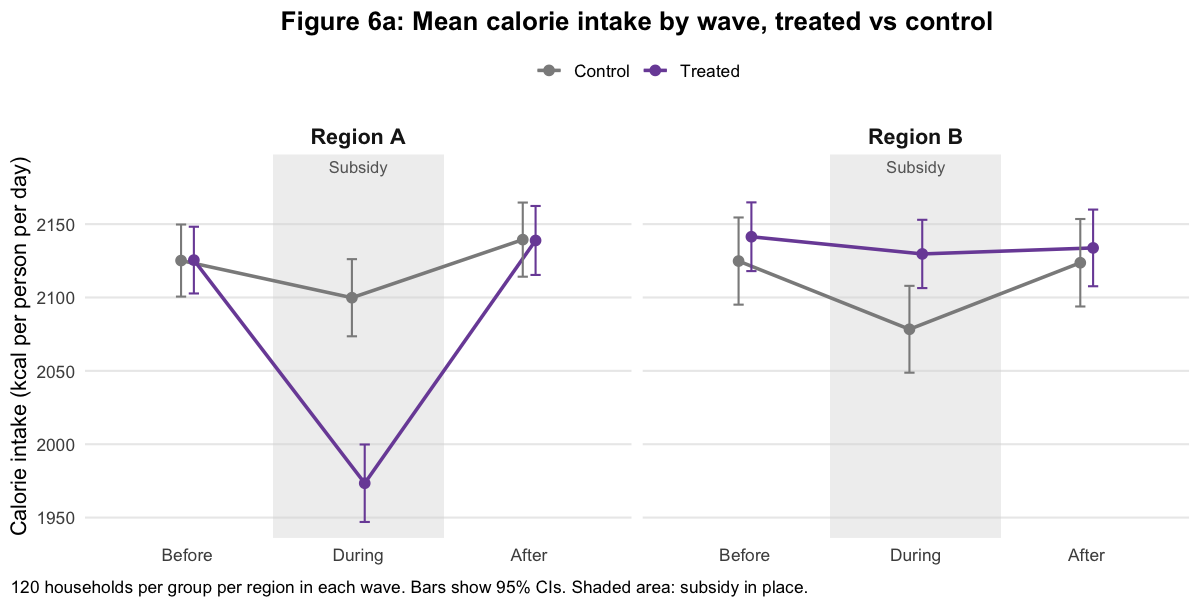

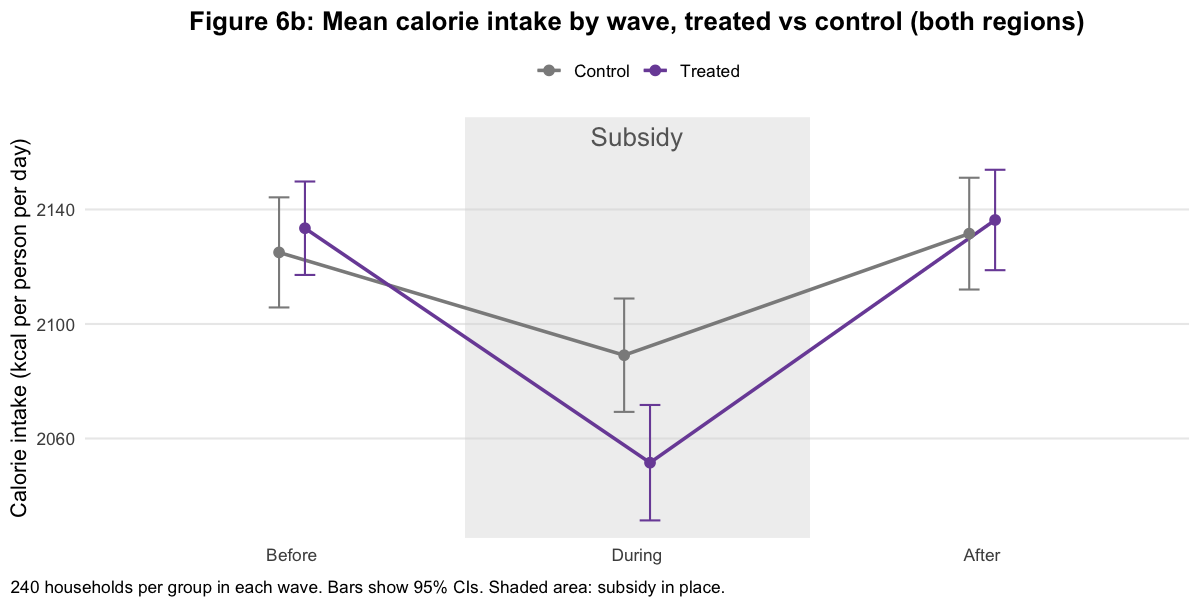

In [65]:
# Plot settings: spacing between groups and figure size
dodge <- position_dodge(0.15)
options(repr.plot.width = 10, repr.plot.height = 5)

# ---- By region ----

# Data: mean and SE of calorie intake by region, wave and group
regression_data |>
  mutate(wave   = factor(wave, levels = c("Before", "During", "After")),
         group  = if_else(treated == 1, "Treated", "Control"),
         region = paste("Region", region)) |>
  group_by(region, wave, group) |>
  summarise(mean_kcal = mean(total_caloric_intake),
            se = sd(total_caloric_intake) / sqrt(n()),
            .groups = "drop") |>

  # Axes: wave on x, mean calories on y, one line per group
  ggplot(aes(wave, mean_kcal, colour = group, group = group)) +

  # Shaded area and label for the During wave (subsidy in place)
  annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf,
           ymax = Inf, fill = "grey85", alpha = 0.4) +
  annotate("text", x = 2, y = Inf, label = "Subsidy",
           vjust = 1.5, colour = "grey40", size = 3.5) +

  # Means with 95% confidence intervals
  geom_line(position = dodge, linewidth = 1) +
  geom_point(position = dodge, size = 2.5) +
  geom_errorbar(aes(ymin = mean_kcal - 1.96 * se, ymax = mean_kcal + 1.96 * se),
                width = 0.12, position = dodge) +

  # One panel per region
  facet_wrap(~ region) +

  # Scales: discrete x axis, extra space on top for the label, group colours
  scale_x_discrete() +
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15))) +
  scale_colour_manual(values = c(Control = "grey55", Treated = "#7b4fa6")) +

  # Titles and notes
  labs(title = "Figure 6a: Mean calorie intake by wave, treated vs control",
       x = NULL, y = "Calorie intake (kcal per person per day)", colour = NULL,
       caption = "120 households per group per region in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +

  # Visual style
  theme_minimal(base_size = 13) +
  theme(legend.position = "top",
        panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        strip.text = element_text(face = "bold", size = 13),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0, vjust = -1),
        plot.caption.position = "plot")

# ---- Both regions ----

# Data: mean and SE of calorie intake by wave and group
regression_data |>
  mutate(wave  = factor(wave, levels = c("Before", "During", "After")),
         group = if_else(treated == 1, "Treated", "Control")) |>
  group_by(wave, group) |>
  summarise(mean_kcal = mean(total_caloric_intake),
            se = sd(total_caloric_intake) / sqrt(n()),
            .groups = "drop") |>

  # Axes: wave on x, mean calories on y, one line per group
  ggplot(aes(wave, mean_kcal, colour = group, group = group)) +

  # Shaded area and label for the During wave (subsidy in place)
  annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf,
           ymax = Inf, fill = "grey85", alpha = 0.4) +
  annotate("text", x = 2, y = Inf, label = "Subsidy",
           vjust = 1.5, colour = "grey40", size = 5.5) +

  # Means with 95% confidence intervals
  geom_line(position = dodge, linewidth = 1) +
  geom_point(position = dodge, size = 2.5) +
  geom_errorbar(aes(ymin = mean_kcal - 1.96 * se, ymax = mean_kcal + 1.96 * se),
                width = 0.12, position = dodge) +

  # Scales: discrete x axis, extra space on top for the label, group colours
  scale_x_discrete() +
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15))) +
  scale_colour_manual(values = c(Control = "grey55", Treated = "#7b4fa6")) +

  # Titles and notes
  labs(title = "Figure 6b: Mean calorie intake by wave, treated vs control (both regions)",
       x = NULL, y = "Calorie intake (kcal per person per day)", colour = NULL,
       caption = "240 households per group in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +

  # Visual style
  theme_minimal(base_size = 13) +
  theme(legend.position = "top",
        panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0, vjust = -1),
        plot.caption.position = "plot")

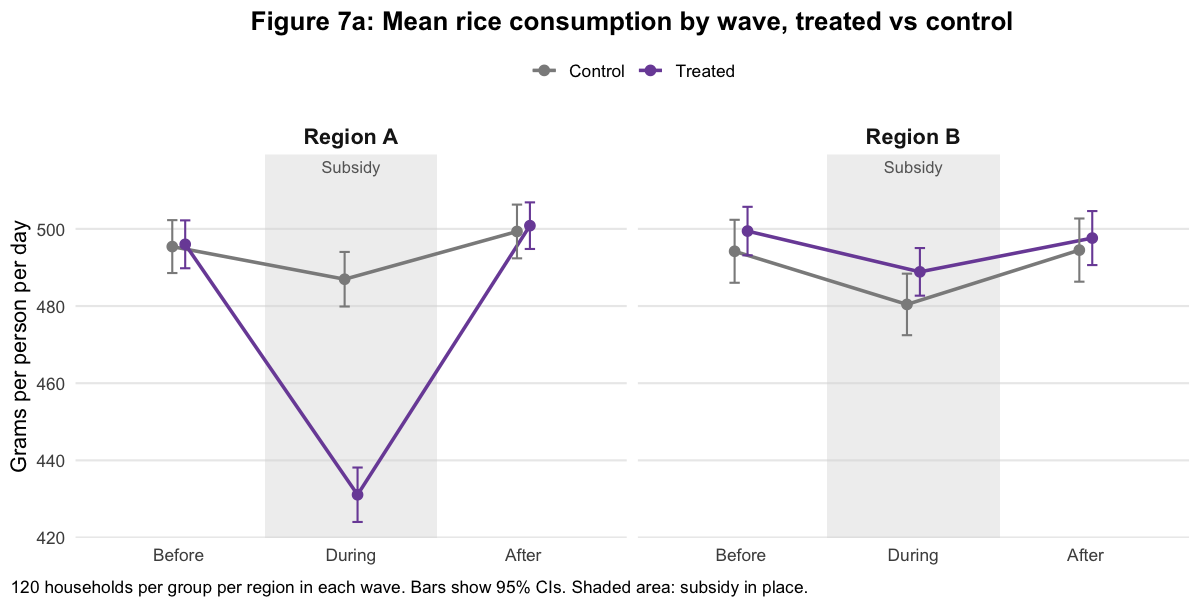

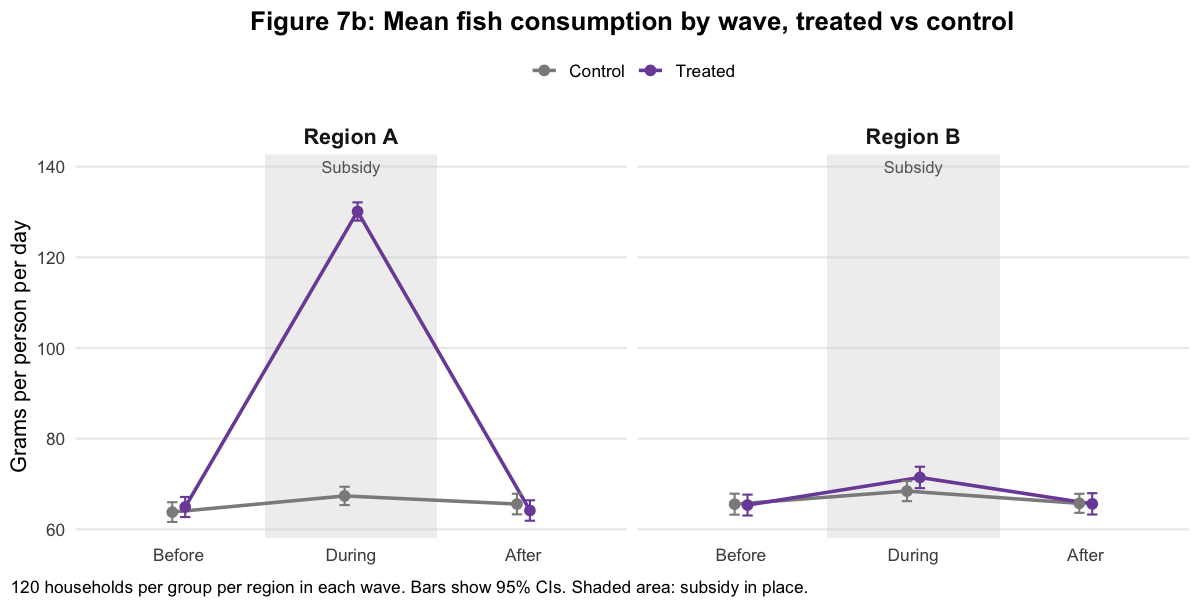

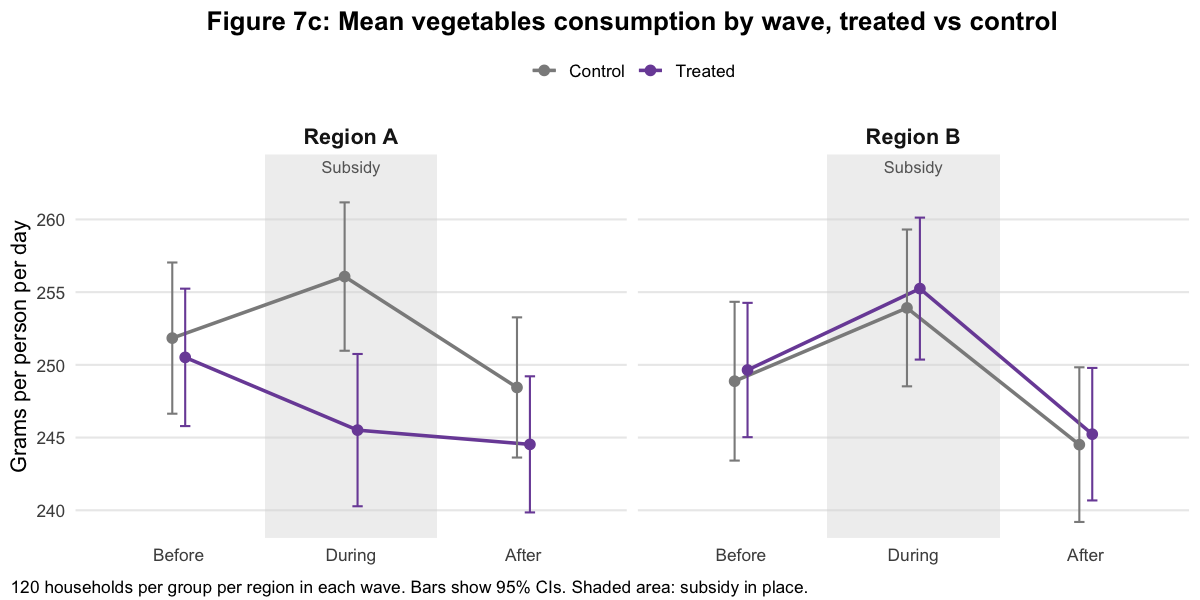

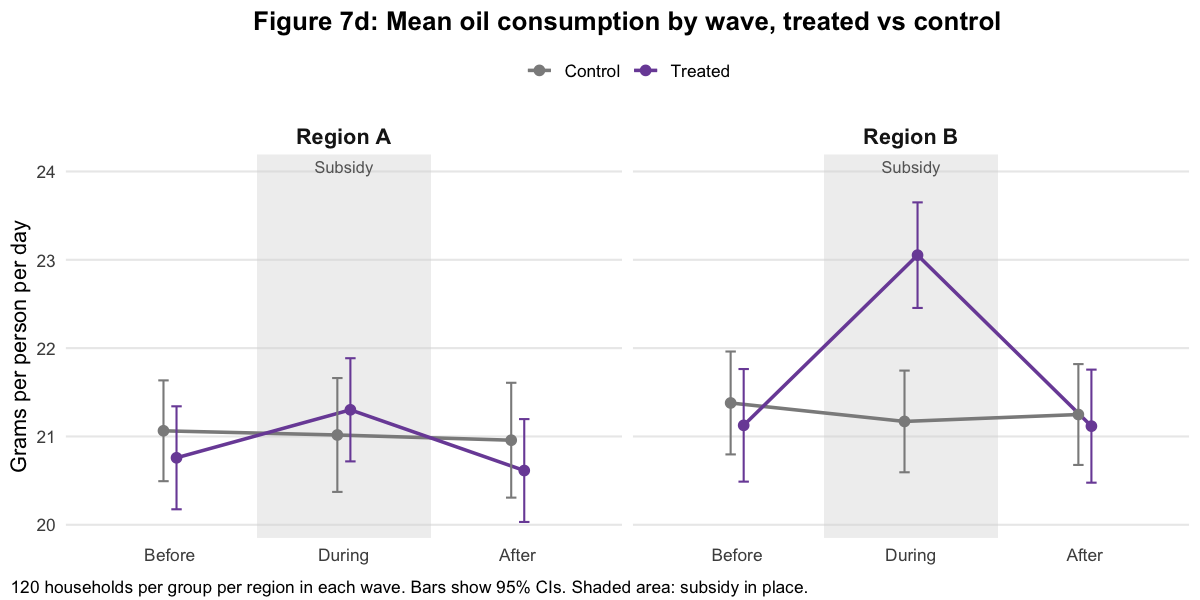

In [66]:
# Plot settings: spacing between groups and figure size
dodge <- position_dodge(0.15)
options(repr.plot.width = 10, repr.plot.height = 5)

# Data: mean and SE of grams consumed by food, region, wave and group
food_means <- raw_data |>
  mutate(wave   = factor(wave, levels = c("Before", "During", "After")),
         group  = if_else(treated == 1, "Treated", "Control"),
         region = paste("Region", region)) |>
  group_by(food, region, wave, group) |>
  summarise(mean = mean(grams_consumed),
            se = sd(grams_consumed) / sqrt(n()),
            .groups = "drop")

foods <- c("rice", "fish", "vegetables", "oil")

# One figure per food
for (f in foods) {
  p <- ggplot(filter(food_means, food == f), aes(wave, mean, colour = group, group = group)) +

    # Shaded area and label for the During wave (subsidy in place)
    annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf,
             ymax = Inf, fill = "grey85", alpha = 0.4) +
    annotate("text", x = 2, y = Inf, label = "Subsidy",
             vjust = 1.5, colour = "grey40", size = 3.5) +

    # Means with 95% confidence intervals
    geom_line(position = dodge, linewidth = 1) +
    geom_point(position = dodge, size = 2.5) +
    geom_errorbar(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se),
                  width = 0.12, position = dodge) +

    # One panel per region
    facet_wrap(~ region) +

    # Scales: discrete x axis, extra space on top for the label, group colours
    scale_x_discrete() +
    scale_y_continuous(expand = expansion(mult = c(0.05, 0.15))) +
    scale_colour_manual(values = c(Control = "grey55", Treated = "#7b4fa6")) +

    # Titles and notes
    labs(title = paste0("Figure 7", letters[which(foods == f)], ": Mean ", f, " consumption by wave, treated vs control"),
         x = NULL, y = "Grams per person per day", colour = NULL,
         caption = "120 households per group per region in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +

    # Visual style
    theme_minimal(base_size = 13) +
    theme(legend.position = "top",
          panel.grid.minor = element_blank(),
          panel.grid.major.x = element_blank(),
          strip.text = element_text(face = "bold", size = 13),
          plot.title = element_text(face = "bold", hjust = 0.5),
          plot.caption = element_text(hjust = 0, vjust = -1),
          plot.caption.position = "plot")

  print(p)
}


##### Question 5: Develop an economic explanation
*How could households’ choices generate the pattern you found? Develop an explanation using the standard consumer choice problem. Specify the relevant goods, the budget constraint and the assumptions about preferences that your argument needs.*

*Use a clearly labelled budget-line and indifference-curve diagram to explain how the price change affects the chosen bundle. Discuss the roles of the substitution and income effects, and whether your explanation requires any goods to be normal or inferior. Connect the logic to your empirical findings. You do not need to estimate a utility function.*

**Economic set-up.** We model a household that chooses between two goods: rice, the staple, and fish, a preferred food that stands for the more costly items in the diet. Rice is the cheapest source of calories (Table 3), while fish offers taste and variety at a much higher cost per calorie. The household divides its budget between the two goods, so the budget constraint is p_rice × rice + p_fish × fish = budget; the subsidy lowers p_rice by 25% for treated households. Preferences reflect two motives: the household needs a minimum level of calories, which rice supplies cheaply, and it values the taste of fish once that minimum is met.

A lower rice price affects the household through two channels. The substitution effect raises rice consumption, since rice becomes cheaper relative to fish. The income effect works through purchasing power: at the new price the household can still afford its original bundle and has resources left over. If rice is an inferior good, the household uses these resources to move away from rice and toward fish. When rice absorbs a large share of the budget, the subsidy frees substantial resources and the income effect can outweigh the substitution effect; rice consumption then falls despite the lower price, and rice behaves as a Giffen good. Jensen and Miller (2011) document this mechanism among poor households in China.

This framework accounts for the patterns in both regions. In region A, treated households cut rice and vegetables and sharply increase fish consumption during the subsidy (Tables 4 and 5): the income effect dominates, rice behaves as a Giffen good, and calorie intake falls. In region B, rice consumption does not change significantly: the two effects roughly offset each other, and the freed resources go mainly to oil and, to a lesser extent, fish. Because oil is the most calorie-dense food, calorie intake rises. The two regions therefore differ in where the freed resources go: toward fish, a costly source of calories, in region A, and toward oil, a dense one, in region B. The data do not reveal why preferences differ across regions; differences in the budget share of rice or in diet composition (Table 2) are candidate explanations.

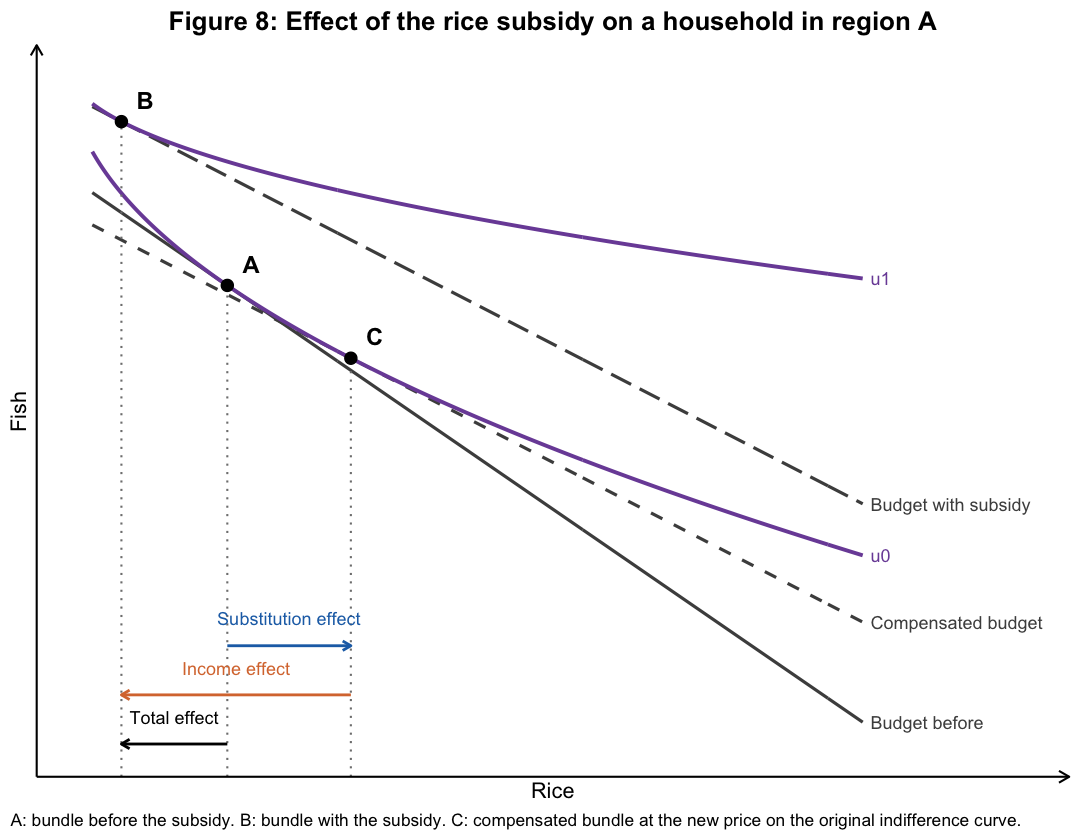

In [70]:
# Illustrative preferences and prices (not estimated; only used to draw the curves)
a  <- 1;  b  <- 2
g1 <- 3;  g2 <- 8
m  <- 10
p_fish <- 1
p_old  <- 1
p_new  <- 0.75

# Utility, rice demand and indifference curve
utility     <- function(x, y) a * log(x - g1) - b * log(g2 - y)
rice_demand <- function(p, m) g1 * b / (b - a) + a * (g2 * p_fish - m) / ((b - a) * p)
ic          <- function(x, u) g2 - ((x - g1)^a * exp(-u))^(1 / b)

# Bundles: A (before), B (with subsidy), C (compensated: new price, original utility)
xA <- rice_demand(p_old, m);  yA <- (m - p_old * xA) / p_fish;  uA <- utility(xA, yA)
xB <- rice_demand(p_new, m);  yB <- (m - p_new * xB) / p_fish;  uB <- utility(xB, yB)
xC <- g1 + exp(-uA) / (b * p_new / (a * p_fish))^2;  yC <- ic(xC, uA)
m_comp <- p_new * xC + p_fish * yC

# Lines to draw
x_grid <- seq(3.15, 8, length.out = 400)

budgets <- bind_rows(
  tibble(x = x_grid, y = (m - p_old * x) / p_fish,      line = "before"),
  tibble(x = x_grid, y = (m - p_new * x) / p_fish,      line = "subsidy"),
  tibble(x = x_grid, y = (m_comp - p_new * x) / p_fish, line = "compensated"))

curves <- bind_rows(
  tibble(x = x_grid, y = ic(x_grid, uA), line = "u0"),
  tibble(x = x_grid, y = ic(x_grid, uB), line = "u1"))

points <- tibble(x = c(xA, xC, xB), y = c(yA, yC, yB), label = c("A", "C", "B"))

# Labels at the right end of each line
x_end <- 8.05
line_labels <- tibble(
  x     = x_end,
  y     = c((m - p_old * 8) / p_fish, (m - p_new * 8) / p_fish, (m_comp - p_new * 8) / p_fish,
            ic(8, uA), ic(8, uB)),
  label = c("Budget before", "Budget with subsidy", "Compensated budget", "u0", "u1"),
  type  = c("budget", "budget", "budget", "ic", "ic"))

# Diagram
options(repr.plot.width = 9, repr.plot.height = 7)

ggplot() +

  # Budget lines and indifference curves
  geom_line(data = budgets, aes(x, y, linetype = line), colour = "grey30", linewidth = 0.9) +
  geom_line(data = curves, aes(x, y, group = line), colour = "#7b4fa6", linewidth = 1.1) +
  geom_text(data = line_labels, aes(x, y, label = label, colour = type),
            hjust = 0, size = 3.8) +

  # Bundles and guides to the rice axis
  annotate("segment", x = points$x, xend = points$x, y = 1.5, yend = points$y,
           linetype = "dotted", colour = "grey50") +
  geom_point(data = points, aes(x, y), size = 3) +
  geom_text(data = points, aes(x, y, label = label),
            nudge_x = 0.15, nudge_y = 0.2, fontface = "bold", size = 5) +

  # Substitution, income and total effects on rice
  annotate("segment", x = xA, xend = xC, y = 2.7, yend = 2.7,
           arrow = arrow(length = unit(0.2, "cm")), colour = "#1f6fb4", linewidth = 0.8) +
  annotate("text", x = (xA + xC) / 2, y = 2.95, label = "Substitution effect", colour = "#1f6fb4", size = 3.8) +
  annotate("segment", x = xC, xend = xB, y = 2.25, yend = 2.25,
           arrow = arrow(length = unit(0.2, "cm")), colour = "#d9773b", linewidth = 0.8) +
  annotate("text", x = (xC + xB) / 2, y = 2.5, label = "Income effect", colour = "#d9773b", size = 3.8) +
  annotate("segment", x = xA, xend = xB, y = 1.8, yend = 1.8,
           arrow = arrow(length = unit(0.2, "cm")), colour = "black", linewidth = 0.8) +
  annotate("text", x = (xA + xB) / 2, y = 2.05, label = "Total effect", colour = "black", size = 3.8) +

  # Scales
  scale_linetype_manual(values = c(before = "solid", subsidy = "longdash", compensated = "dashed"),
                        guide = "none") +
  scale_colour_manual(values = c(budget = "grey30", ic = "#7b4fa6"), guide = "none") +
  coord_cartesian(xlim = c(2.8, 9.3), ylim = c(1.5, 8.2), expand = FALSE) +

  # Titles and notes
  labs(title = "Figure 8: Effect of the rice subsidy on a household in region A",
       x = "Rice", y = "Fish",
       caption = "A: bundle before the subsidy. B: bundle with the subsidy. C: compensated bundle at the new price on the original indifference curve.") +

  # Textbook style: axes only, no numbers or grid
  theme_minimal(base_size = 13) +
  theme(panel.grid = element_blank(),
        axis.text = element_blank(),
        axis.line = element_line(colour = "black", arrow = arrow(length = unit(0.25, "cm"))),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

##### Question 6: Look for evidence of the mechanism
*Turn your explanation into predictions that you can investigate in the data. What patterns would strengthen it? What would cast doubt on it? Design and present the tables, plots or other comparisons that you judge most informative, and explain what each one establishes.*

*Consider at least one plausible alternative explanation and assess how far the available evidence distinguishes between the two. Be precise about the difference between describing a pattern and establishing why households chose it. Revise your explanation if your evidence calls for it, and identify any additional information you would need.*

It is important to take into account what Figure X shows. The bars for each food add up to the total effect of the subsidy on calorie intake in each region. For region A, we can clearly see that there are two dominating effects: the calories from fish increased, while the calories from rice decreased by much more. This is compatible with what we estimated in Tables 3, 4 and 5, since households replaced rice with fish, which provides fewer calories per gram.

However, for region B the effect on calories from rice is positive but not statistically significant, and the increase is mainly driven by oil (table 5). This explains why the households in this region experienced an increase in calorie intake. This does not imply that region B is eating healthier, since we do not have information about the evolution in the consumption of micronutrients or proteins. For the same reason, we cannot say that region A is eating worse, as fish may provide more protein than rice.

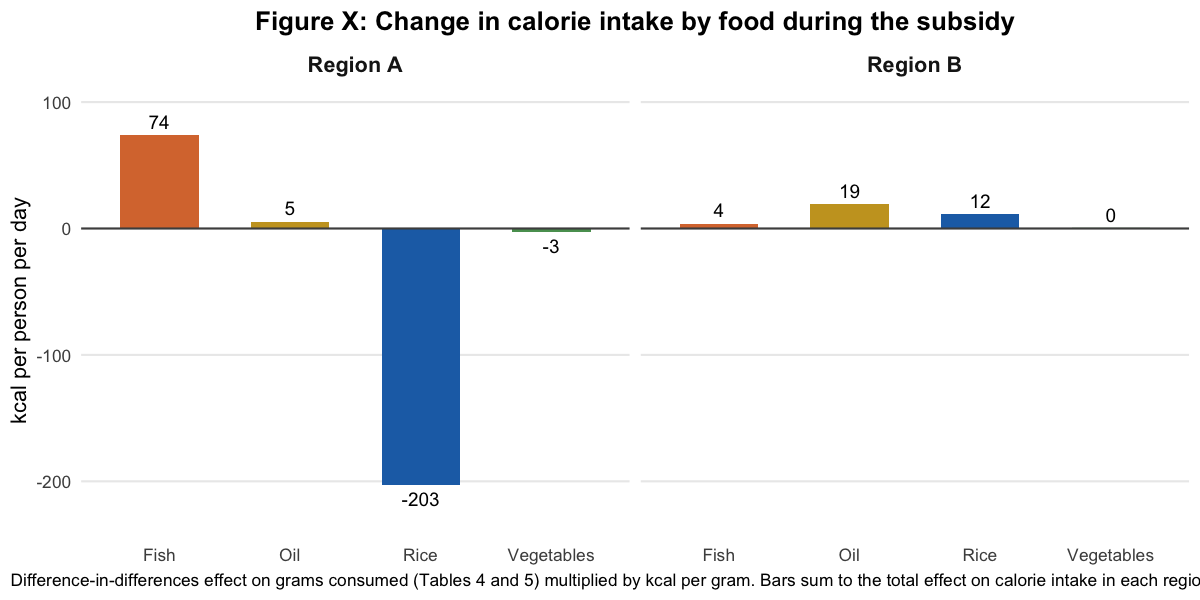

In [72]:
kcal_per_g <- c(rice = 3.6, fish = 1.2, vegetables = 0.3, oil = 9.0)

# Effect of the subsidy on calories from each food, by region
decomp <- expand_grid(food = names(kcal_per_g), region = c("A", "B")) |>
  rowwise() |>
  mutate(grams = coef(regression_per_food(food, region))["treated:wave_during"]) |>
  ungroup() |>
  mutate(kcal   = grams * kcal_per_g[food],
         food   = str_to_title(food),
         region = paste("Region", region))

# Diverging bar chart
options(repr.plot.width = 10, repr.plot.height = 5)

ggplot(decomp, aes(food, kcal, fill = food)) +
  geom_col(width = 0.6) +
  geom_hline(yintercept = 0, colour = "grey30") +
  geom_text(aes(label = round(kcal), vjust = if_else(kcal >= 0, -0.5, 1.5)), size = 4) +
  facet_wrap(~ region) +
  scale_fill_manual(values = c(Rice = "#1f6fb4", Oil = "#c9a227",
                               Fish = "#d9773b", Vegetables = "#5a9e5f"),
                    guide = "none") +
  scale_y_continuous(expand = expansion(mult = 0.15)) +
  labs(title = "Figure X: Change in calorie intake by food during the subsidy",
       x = NULL, y = "kcal per person per day",
       caption = "Difference-in-differences effect on grams consumed (Tables 4 and 5) multiplied by kcal per gram. Bars sum to the total effect on calorie intake in each region.") +
  theme_minimal(base_size = 13) +
  theme(panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        strip.text = element_text(face = "bold", size = 13),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

In [73]:
spend_data <- filter(food_data, food == "rice")

spend_model <- function(v, r) {
  feols(as.formula(paste(v, "~ treated:wave_during + treated:wave_after | household_id + wave")),
        data = filter(spend_data, region == r), cluster = ~household_id)
}

tbl8 <- modelsummary(list("Food spending, A"  = spend_model("food_spending", "A"),
                          "Food spending, B"  = spend_model("food_spending", "B"),
                          "Other spending, A" = spend_model("other_spending", "A"),
                          "Other spending, B" = spend_model("other_spending", "B")),
                     coef_map = c("treated:wave_during" = "Treated × During",
                                  "treated:wave_after"  = "Treated × After"),
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs"),
                     output  = "gt") |>
  tab_header(title = "Table 6: Effect of the rice subsidy on spending, by region") |>
  tab_source_note("Dependent variable: currency units per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl8))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: currency units per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.


##### Question 7: Brief the policymaker
*Write a 200–300 word briefing answering the government’s question: should it expand, revise or discontinue the programme? Ground your recommendation in your evidence and explain the main mechanism in plain language.*

*Does your verdict on the policy’s stated objective also determine whether households are better orworse off? Explain. Identify the most useful additional evidence or policy test before a final decision, and be clear about the limits of what this pilot establishes.*